# Phân tích cảm xúc tiếng Việt với Word Embedding (TensorFlow)
### Project 04: Analyse de Sentiments avec Word Embedding

**Dữ liệu:** UIT-VSFC (Vietnamese Students' Feedback Corpus), khoảng 16.000 câu phản hồi của sinh viên về giảng viên, môn học và cơ sở vật chất.

**Mục tiêu:** xây mô hình đọc một câu nhận xét tiếng Việt và cho biết câu đó **tích cực** hay **tiêu cực**, rồi cho phép tự gõ câu vào để thử.

| Bước | Nội dung | Liên hệ bài giảng |
|---|---|---|
| 1 | Cài đặt và import | |
| 2 | Tải dữ liệu UIT-VSFC | |
| 3 | Khám phá dữ liệu (EDA) | |
| 4 | Chọn nhãn: bỏ câu trung tính, giữ 2 lớp | |
| 5 | Làm sạch và tách từ tiếng Việt | 3.3 Tokenizer |
| 6 | Tokenizer, text-to-sequence, padding | 3.1, 3.2, 3.4 |
| 7 | Xây mô hình Embedding + Bi-LSTM | 3.5, 2.2 (RNN cho sentiment) |
| 8 | Huấn luyện | |
| 9 | Đánh giá trên tập test | |
| 10 | Phân tích word embedding đã học | 3.5, 2.2 (cosine similarity) |
| 11 | Lưu và nạp lại mô hình | |
| 12 | **Test bằng câu tự gõ** | |
| 13 | Kết luận | |

## Bước 1. Cài đặt và import thư viện

- **Google Colab:** TensorFlow đã có sẵn, chỉ cần cài `datasets` (tải dữ liệu từ Hugging Face) `pyvi` (tách từ tiếng Việt) và `ipywidgets` (ô nhập chữ ở Bước 12).
- **Máy cá nhân:** cài thêm `tensorflow tf-keras scikit-learn matplotlib pandas`.

In [1]:
%pip install -q datasets pyvi ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import json
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from datasets import load_dataset
from pyvi import ViTokenizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Tokenizer của Keras (dùng trong bài 3.1-3.5).
# TF <= 2.15 có sẵn trong tensorflow.keras; TF >= 2.16 (Keras 3) phải lấy từ gói tf_keras.
try:
    from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json
except ImportError:
    from tf_keras.preprocessing.text import Tokenizer, tokenizer_from_json
from tensorflow.keras.utils import pad_sequences

tf.keras.utils.set_random_seed(42)   # để kết quả lặp lại được giữa các lần chạy
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0


GPU: []


## Bước 2. Tải dữ liệu UIT-VSFC

Bộ dữ liệu gốc trên Hugging Face dùng script tải cũ, mà thư viện `datasets` từ bản 4.0 không chạy script nữa. Vì vậy ta tải **bản parquet** mà Hugging Face đã chuyển sẵn (`revision="refs/convert/parquet"`).

Mỗi dòng có 3 cột:
- `sentence`: câu phản hồi
- `sentiment`: 0 = tiêu cực, 1 = trung tính, 2 = tích cực
- `topic`: chủ đề (không dùng trong project này)

In [3]:
ds = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")
ds

DatasetDict({
    train: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 11426
    })
    validation: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 1583
    })
    test: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 3166
    })
})

In [4]:
train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()

SENTIMENT_NAMES = {0: "tiêu cực", 1: "trung tính", 2: "tích cực"}
print("train:", train_df.shape, " validation:", val_df.shape, " test:", test_df.shape)
train_df.head(10)

train: (11426, 3)  validation: (1583, 3)  test: (3166, 3)


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0
5,"giảng viên đảm bảo thời gian lên lớp , tích cự...",2,0
6,"em sẽ nợ môn này , nhưng em sẽ học lại ở các h...",1,3
7,"thời lượng học quá dài , không đảm bảo tiếp th...",0,1
8,"nội dung môn học có phần thiếu trọng tâm , hầu...",0,1
9,cần nói rõ hơn bằng cách trình bày lên bảng th...,0,1


## Bước 3. Khám phá dữ liệu (EDA)

### 3.1 Phân bố nhãn

sentiment
tích cực      5643
tiêu cực      5325
trung tính     458
Name: count, dtype: int64


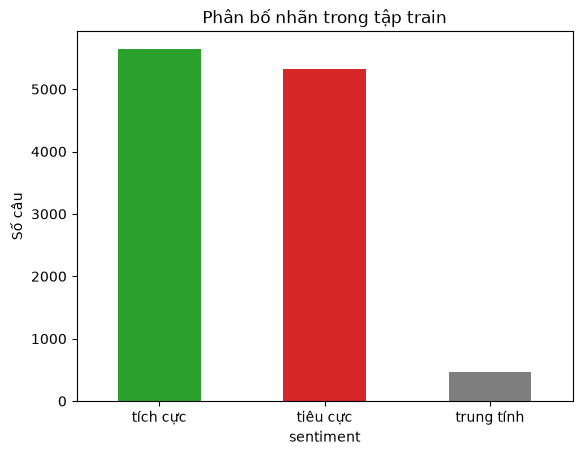

In [5]:
counts = train_df["sentiment"].map(SENTIMENT_NAMES).value_counts()
print(counts)

counts.plot(kind="bar", color=["tab:green", "tab:red", "tab:gray"], rot=0)
plt.title("Phân bố nhãn trong tập train")
plt.ylabel("Số câu")
plt.show()

**Nhận xét:** tích cực và tiêu cực gần cân bằng, còn trung tính chỉ chiếm khoảng 4%. Mô hình gần như không học được lớp này, nên ở bước 4 ta sẽ bỏ các câu trung tính.

### 3.2 Độ dài câu (tính theo số từ)

count    11426.000000
mean        14.308769
std         10.089727
min          2.000000
25%          8.000000
50%         11.000000
75%         17.000000
max        159.000000
Name: sentence, dtype: float64


95% số câu có độ dài <= 33 từ


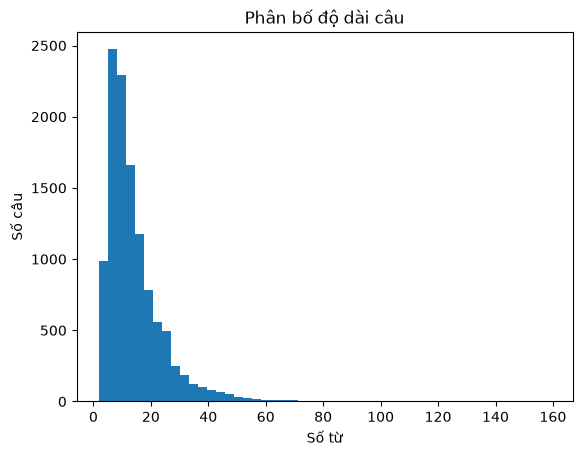

In [6]:
lengths = train_df["sentence"].str.split().str.len()
print(lengths.describe())
print("95% số câu có độ dài <=", int(np.percentile(lengths, 95)), "từ")

plt.hist(lengths, bins=50)
plt.title("Phân bố độ dài câu")
plt.xlabel("Số từ")
plt.ylabel("Số câu")
plt.show()

**Nhận xét:** câu rất ngắn so với review IMDB (vài trăm từ). Số liệu này giúp chọn `max_length` ở bước 6.

### 3.3 Một vài câu mẫu theo từng nhãn

In [7]:
for label, name in SENTIMENT_NAMES.items():
    print(f"--- {name.upper()} ---")
    for s in train_df[train_df["sentiment"] == label]["sentence"].head(4):
        print("  •", s)

--- TIÊU CỰC ---
  • đi học đầy đủ full điểm chuyên cần .
  • chưa áp dụng công nghệ thông tin và các thiết bị hỗ trợ cho việc giảng dạy .
  • thời lượng học quá dài , không đảm bảo tiếp thu hiệu quả .
  • nội dung môn học có phần thiếu trọng tâm , hầu như là chung chung , khái quát khiến sinh viên rất khó nắm được nội dung môn học .
--- TRUNG TÍNH ---
  • em sẽ nợ môn này , nhưng em sẽ học lại ở các học kỳ kế tiếp .
  • đang dạy thầy wzjwz208 đi qua nước ngoài giữa chừng , thầy wzjwz209 dạy thay .
  • tạo ra sự cạnh tranh trong mỗi buổi thực hành .
  • ôn tập đúng theo thầy nhưng không biết cuối kỳ được mấy điểm .
--- TÍCH CỰC ---
  • slide giáo trình đầy đủ .
  • nhiệt tình giảng dạy , gần gũi với sinh viên .
  • thầy giảng bài hay , có nhiều bài tập ví dụ ngay trên lớp .
  • giảng viên đảm bảo thời gian lên lớp , tích cực trả lời câu hỏi của sinh viên , thường xuyên đặt câu hỏi cho sinh viên .


## Bước 4. Chọn nhãn: bỏ câu trung tính, giữ 2 lớp

Bài toán trở thành **phân loại nhị phân** giống bài 3.5:
- `0` = tiêu cực
- `1` = tích cực (nhãn gốc 2)

In [8]:
LABEL_NAMES = ["tiêu cực", "tích cực"]

def keep_two_classes(df):
    df = df[df["sentiment"] != 1].copy()          # bỏ trung tính
    df["label"] = (df["sentiment"] == 2).astype(int)
    return df[["sentence", "label"]].reset_index(drop=True)

train_df2 = keep_two_classes(train_df)
val_df2   = keep_two_classes(val_df)
test_df2  = keep_two_classes(test_df)

for name, df in [("train", train_df2), ("validation", val_df2), ("test", test_df2)]:
    print(f"{name:<11} {len(df):>6} câu  | tích cực: {df['label'].mean():.1%}")

train        10968 câu  | tích cực: 51.4%
validation    1510 câu  | tích cực: 53.3%
test          2999 câu  | tích cực: 53.0%


## Bước 5. Làm sạch và tách từ tiếng Việt

Tiếng Việt có rất nhiều **từ ghép nhiều âm tiết**: "giảng viên", "nhiệt tình", "sinh viên". Nếu chỉ tách theo dấu cách thì "giảng" và "viên" bị coi là 2 từ riêng và mất nghĩa.

Thư viện **pyvi** nối các âm tiết của một từ bằng dấu `_`, ví dụ `giảng_viên`, `nhiệt_tình`. Mỗi từ ghép sẽ thành **một token** và có **một vector embedding** riêng.

Các bước xử lý:
1. Chuyển chữ thường
2. Bỏ dấu câu, ký tự đặc biệt và chữ số
3. **Chuẩn hoá i/y**: tiếng Việt cho phép viết "kĩ" hoặc "kỹ", "lí" hoặc "lý". Với Tokenizer đây là 2 từ khác nhau. Trong UIT-VSFC sinh viên gần như luôn viết bằng **y** (`kỹ` 203 lần, `lý_thuyết` 362 lần, còn `kĩ`, `lí` thì 0 lần). Nếu không chuẩn hoá, câu "Bài giảng soạn kĩ" sẽ thành `bài giảng soạn <OOV>` và bị đoán **tiêu cực**. Vì vậy ta đổi các âm tiết `kĩ, kí, lí, mĩ` sang `kỹ, ký, lý, mỹ`.
4. Tách từ bằng `ViTokenizer`

In [9]:
# Chuẩn hoá i/y theo cách viết phổ biến trong dữ liệu (kĩ -> kỹ, lí thuyết -> lý thuyết, ...)
I_Y = {"kĩ": "kỹ", "kí": "ký", "lí": "lý", "mĩ": "mỹ"}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)   # bỏ dấu câu, giữ chữ cái tiếng Việt có dấu
    text = re.sub(r"\d+", " ", text)        # bỏ chữ số
    text = " ".join(I_Y.get(w, w) for w in text.split())   # chuẩn hoá i/y
    return text

def preprocess(text):
    return ViTokenizer.tokenize(clean_text(text))

# Xem trước / sau khi xử lý
for s in train_df2["sentence"].head(5):
    print("Gốc   :", s)
    print("Xử lý :", preprocess(s))
    print()

print("Gốc   : Bài giảng soạn kĩ, lí thuyết rõ ràng")
print("Xử lý :", preprocess("Bài giảng soạn kĩ, lí thuyết rõ ràng"))

Gốc   : slide giáo trình đầy đủ .
Xử lý : slide giáo_trình đầy_đủ

Gốc   : nhiệt tình giảng dạy , gần gũi với sinh viên .
Xử lý : nhiệt_tình giảng_dạy gần_gũi với sinh_viên

Gốc   : đi học đầy đủ full điểm chuyên cần .
Xử lý : đi học đầy_đủ full điểm chuyên_cần

Gốc   : chưa áp dụng công nghệ thông tin và các thiết bị hỗ trợ cho việc giảng dạy .
Xử lý : chưa áp_dụng công_nghệ thông_tin và các thiết_bị hỗ_trợ cho việc giảng_dạy

Gốc   : thầy giảng bài hay , có nhiều bài tập ví dụ ngay trên lớp .
Xử lý : thầy giảng bài hay có nhiều bài_tập ví_dụ ngay trên lớp

Gốc   : Bài giảng soạn kĩ, lí thuyết rõ ràng
Xử lý : bài giảng soạn kỹ lý_thuyết rõ_ràng


In [10]:
%%time
train_texts = [preprocess(s) for s in train_df2["sentence"]]
val_texts   = [preprocess(s) for s in val_df2["sentence"]]
test_texts  = [preprocess(s) for s in test_df2["sentence"]]

train_labels = train_df2["label"].to_numpy()
val_labels   = val_df2["label"].to_numpy()
test_labels  = test_df2["label"].to_numpy()

CPU times: total: 1.55 s
Wall time: 1.56 s


## Bước 6. Tokenizer, text-to-sequence và padding (bài 3.1, 3.2, 3.4)

- **Tokenizer** (bài 3.1): xây từ điển `từ → số`, học **chỉ trên tập train**.
- `oov_token="<OOV>"` (bài 3.2): từ chưa gặp khi học sẽ được thay bằng `<OOV>`, thay vì bị bỏ mất.
- `filters`: mặc định Tokenizer xoá cả dấu `_`, như vậy sẽ phá các từ ghép `giảng_viên`. Ta bỏ `_` khỏi danh sách filters.
- **texts_to_sequences** (bài 3.2): đổi câu thành dãy số.
- **pad_sequences** (bài 3.4): đệm hoặc cắt để mọi câu dài bằng `max_length`.

In [11]:
oov_tok = "<OOV>"
FILTERS = '!"#$%&()*+,-./:;<=>?@[\\]^`{|}~\t\n'   # filters mặc định nhưng KHÔNG có dấu '_'

tokenizer = Tokenizer(oov_token=oov_tok, filters=FILTERS)
tokenizer.fit_on_texts(train_texts)
word_index = tokenizer.word_index

# Giới hạn từ điển: tối đa 5000 từ phổ biến nhất
vocab_size = min(5000, len(word_index) + 1)
tokenizer.num_words = vocab_size

print("Số từ khác nhau trong tập train:", len(word_index))
print("vocab_size dùng cho mô hình    :", vocab_size)
print("10 từ phổ biến nhất:", list(word_index.items())[:10])

Số từ khác nhau trong tập train: 3364
vocab_size dùng cho mô hình    : 3365
10 từ phổ biến nhất: [('<OOV>', 1), ('thầy', 2), ('sinh_viên', 3), ('dạy', 4), ('và', 5), ('rất', 6), ('không', 7), ('nhiệt_tình', 8), ('cho', 9), ('hiểu', 10)]


In [12]:
train_sequences = tokenizer.texts_to_sequences(train_texts)
seq_lengths = [len(s) for s in train_sequences]

# Chọn max_length phủ được 95% số câu (sau khi tách từ)
max_length = int(np.percentile(seq_lengths, 95))
padding_type = "post"   # đệm số 0 ở CUỐI câu
trunc_type = "post"     # câu dài hơn max_length thì cắt phần CUỐI
print("max_length =", max_length)

def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=max_length, padding=padding_type, truncating=trunc_type)

train_padded = to_padded(train_texts)
val_padded   = to_padded(val_texts)
test_padded  = to_padded(test_texts)

print("train_padded:", train_padded.shape)
print("val_padded  :", val_padded.shape)
print("test_padded :", test_padded.shape)
print()
print("Câu      :", train_texts[0])
print("Sequence :", train_sequences[0])
print("Padded   :", train_padded[0])

max_length = 24


train_padded: (10968, 24)
val_padded  : (1510, 24)
test_padded : (2999, 24)

Câu      : slide giáo_trình đầy_đủ
Sequence : [80, 199, 95]
Padded   : [ 80 199  95   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0]


## Bước 7. Xây mô hình (bài 3.5 và bài 2.2)

```
Input (max_length)
 → Embedding(vocab_size, 64, mask_zero=True)   mỗi từ thành một vector 64 chiều
 → Bidirectional(LSTM(64))                     đọc câu theo cả 2 chiều, giữ thứ tự từ
 → Dropout(0.5)                                giảm overfit
 → Dense(32, relu)
 → Dense(1, sigmoid)                           xác suất câu là tích cực
```

- **Embedding**: giống bài 3.5. Ma trận `vocab_size × 64` được học cùng mô hình.
- **Vì sao dùng LSTM thay vì Flatten như bài 3.5**: bài 2.2 chỉ ra rằng cách cộng hoặc trung bình các vector từ sẽ **bỏ qua thứ tự từ**. Với câu như *"thầy dạy không hay"*, chữ "không" đứng trước "hay" làm đảo nghĩa. RNN/LSTM đọc câu lần lượt từng từ nên nắm được điều này.
- **mask_zero=True**: báo cho LSTM bỏ qua các số 0 do padding thêm vào.

In [13]:
embedding_dim = 64

model = tf.keras.Sequential([
    tf.keras.Input(shape=(max_length,)),
    tf.keras.layers.Embedding(vocab_size, embedding_dim, mask_zero=True, name="embedding"),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 24, 64)         │       215,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 285,569 (1.09 MB)

 Trainable params: 285,569 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

## Bước 8. Huấn luyện

- Dùng **tập validation có sẵn** của UIT-VSFC để theo dõi, giữ tập test riêng cho bước đánh giá cuối.
- **EarlyStopping**: dừng khi `val_loss` không giảm sau 3 epoch và quay lại trọng số tốt nhất.

In [14]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                              restore_best_weights=True)

history = model.fit(train_padded, train_labels,
                    validation_data=(val_padded, val_labels),
                    epochs=20, batch_size=64,
                    callbacks=[early_stop],
                    verbose=2)   # in gọn mỗi epoch một dòng

Epoch 1/20


172/172 - 4s - 25ms/step - accuracy: 0.8899 - loss: 0.3033 - val_accuracy: 0.9437 - val_loss: 0.1672


Epoch 2/20


172/172 - 2s - 9ms/step - accuracy: 0.9507 - loss: 0.1457 - val_accuracy: 0.9477 - val_loss: 0.1569


Epoch 3/20


172/172 - 2s - 9ms/step - accuracy: 0.9638 - loss: 0.1155 - val_accuracy: 0.9470 - val_loss: 0.1623


Epoch 4/20


172/172 - 2s - 9ms/step - accuracy: 0.9712 - loss: 0.0972 - val_accuracy: 0.9444 - val_loss: 0.1763


Epoch 5/20


172/172 - 2s - 9ms/step - accuracy: 0.9747 - loss: 0.0829 - val_accuracy: 0.9417 - val_loss: 0.1855


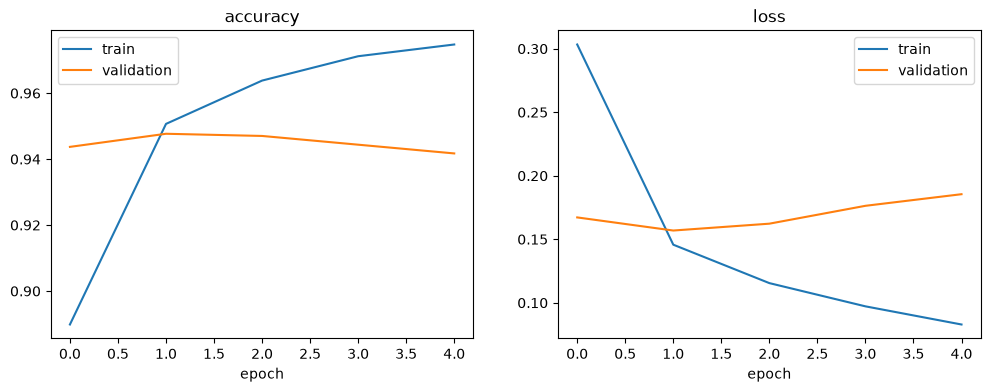

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.plot(history.history[metric], label="train")
    ax.plot(history.history["val_" + metric], label="validation")
    ax.set_title(metric)
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

**Nhận xét:** mô hình học rất nhanh, `val_loss` thấp nhất chỉ sau khoảng 2 epoch. Sau đó train accuracy tiếp tục tăng còn `val_loss` lại tăng, tức là mô hình bắt đầu **overfit** (học thuộc tập train). EarlyStopping dừng huấn luyện và quay lại trọng số ở epoch tốt nhất.

## Bước 9. Đánh giá trên tập test

Tập test chưa từng được dùng khi huấn luyện, nên đây là con số phản ánh đúng chất lượng mô hình.

In [16]:
test_probs = model.predict(test_padded, verbose=0).ravel()
test_preds = (test_probs >= 0.5).astype(int)

print(f"Accuracy trên tập test: {accuracy_score(test_labels, test_preds):.4f}\n")
print(classification_report(test_labels, test_preds, target_names=LABEL_NAMES, digits=4))

Accuracy trên tập test: 0.9366

              precision    recall  f1-score   support

    tiêu cực     0.9028    0.9695    0.9350      1409
    tích cực     0.9711    0.9075    0.9382      1590

    accuracy                         0.9366      2999
   macro avg     0.9370    0.9385    0.9366      2999
weighted avg     0.9390    0.9366    0.9367      2999



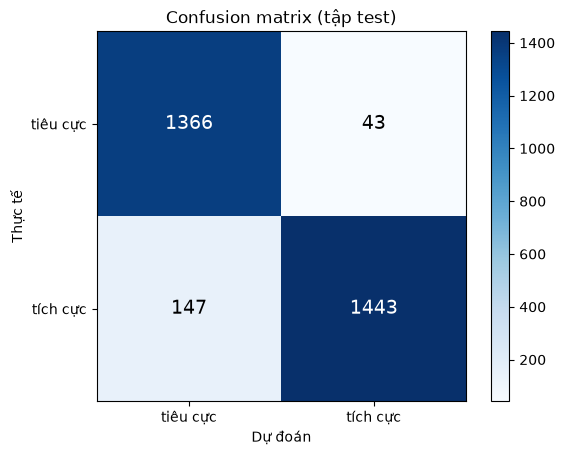

In [17]:
cm = confusion_matrix(test_labels, test_preds)

plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], LABEL_NAMES)
plt.yticks([0, 1], LABEL_NAMES)
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.title("Confusion matrix (tập test)")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.colorbar()
plt.show()

### Một số câu mô hình đoán sai

In [18]:
wrong = test_df2.assign(pred=test_preds, prob_tich_cuc=test_probs.round(3))
wrong = wrong[wrong["label"] != wrong["pred"]]
wrong["thực tế"] = wrong["label"].map(dict(enumerate(LABEL_NAMES)))
wrong["dự đoán"] = wrong["pred"].map(dict(enumerate(LABEL_NAMES)))
print("Số câu sai:", len(wrong), "/", len(test_df2))

pd.set_option("display.max_colwidth", 120)
wrong[["sentence", "thực tế", "dự đoán", "prob_tich_cuc"]].head(15)

Số câu sai: 190 / 2999


,sentence,thực tế,dự đoán,prob_tich_cuc
6,tính điểm thi đua các nhóm .,tích cực,tiêu cực,0.476
12,trong trường macbook thầy số hai thì không có máy nào số một .,tích cực,tiêu cực,0.040
42,phần lớn chỉ là lý thuyết và bài tập .,tích cực,tiêu cực,0.071
51,"ấn tượng nhất doubledot dạy không cần máy chiếu hay laptop , nhưng lượng bài giảng có thể nói là "" khủng "" , nhìn th...",tích cực,tiêu cực,0.016
53,đưa nhiều bài tập khó mà có lời giải cho sinh viên về nhà nghiên cứu .,tích cực,tiêu cực,0.040
59,rất thực tế không dài dòng .,tích cực,tiêu cực,0.109
65,tính thực tế cũng cao so với việc thi lý thuyết lấy điểm .,tích cực,tiêu cực,0.421
87,cách dạy đổi mới .,tích cực,tiêu cực,0.264
117,cần có nhiều giảng viên như cô dạy hơn .,tích cực,tiêu cực,0.011
147,rất hài lòng nên không có gì không hài lòng .,tích cực,tiêu cực,0.016


## Bước 10. Phân tích word embedding đã học (bài 3.5 và bài 2.2)

Lớp Embedding là một ma trận `vocab_size × 64`: mỗi hàng là vector của một từ. Mô hình chỉ được dạy đoán nhãn tích cực hay tiêu cực, nhưng trong lúc học nó tự đẩy các từ có cùng cảm xúc lại gần nhau.

Ta đo độ gần giữa hai từ bằng **cosine similarity** (bài 2.2):  `cos(u, v) = u·v / (‖u‖·‖v‖)`

In [19]:
weights = model.get_layer("embedding").get_weights()[0]
print("Kích thước ma trận embedding:", weights.shape)   # (vocab_size, embedding_dim)

reverse_word_index = {idx: w for w, idx in word_index.items() if idx < vocab_size}
norms = np.linalg.norm(weights, axis=1) + 1e-9

def nearest_words(word, top_k=8):
    idx = word_index.get(word)
    if idx is None or idx >= vocab_size:
        print(f"'{word}' không có trong từ điển")
        return
    sims = weights @ weights[idx] / (norms * norms[idx])
    result = []
    for i in np.argsort(-sims):
        if i in (0, 1, idx):            # bỏ padding (0), <OOV> (1) và chính từ đó
            continue
        result.append(f"{reverse_word_index[i]} ({sims[i]:.2f})")
        if len(result) == top_k:
            break
    print(f"{word:>12} → " + ", ".join(result))

for w in ["hay", "nhiệt_tình", "tốt", "tận_tình", "chán", "buồn_ngủ", "nhanh", "thiếu"]:
    nearest_words(w)

Kích thước ma trận embedding: (3365, 64)
         hay → vui_tính (0.70), tuyệt_vời (0.68), hướng_dẫn_nhiệt_tình (0.68), vui (0.67), gần_gũi (0.67), sinh_động (0.67), học_viên (0.66), đầy_đủ (0.66)
  nhiệt_tình → vui_tính (0.86), vui (0.86), thoải_mái (0.84), tâm_huyết (0.83), thân_thiện (0.83), đầy_đủ (0.82), tận_tình (0.82), tuyệt_vời (0.82)
         tốt → vui_tính (0.86), tuyệt_vời (0.85), thân_thiện (0.84), thoải_mái (0.84), cảm_ơn (0.84), vui (0.83), truyền_cảm_hứng (0.83), giỏi (0.83)
    tận_tình → nhiệt_tình (0.82), tốt (0.81), vui_tính (0.81), tuyệt_vời (0.81), thân_thiện (0.80), thoải_mái (0.79), vui (0.79), đầy_đủ (0.79)
        chán → buồn_ngủ (0.90), khó (0.89), chưa (0.89), ít (0.88), nghỉ (0.87), đầu_tư (0.87), hạn_chế (0.86), hơi (0.86)
    buồn_ngủ → sai (0.93), trễ (0.92), khó (0.92), chưa (0.90), thay_vì (0.90), chán (0.90), mất (0.89), muộn (0.89)
       nhanh → khó (0.82), chưa (0.77), mơ_hồ (0.77), nghỉ (0.76), trễ (0.76), chênh_lệch (0.75), thay_vì (0.75), kênh (0

**Nhận xét:** các từ khen (`hay`, `nhiệt_tình`, `tốt`) có hàng xóm gần nhất cũng là từ khen (`vui_tính`, `tuyệt_vời`, `thân_thiện`…). Các từ chê (`chán`, `buồn_ngủ`) gần với `khó`, `thiếu`, `chưa`… Đáng chú ý là `nhanh` tự nằm vào nhóm tiêu cực, vì trong phản hồi sinh viên "dạy nhanh quá" là một lời chê. **Nghĩa cảm xúc của từ được học ra từ nhãn của dữ liệu**, đúng như slide 19 của bài 3.5.

### Trực quan hoá embedding trên mặt phẳng 2D (PCA)

Chiếu vector 64 chiều xuống 2 chiều để xem các từ tích cực và tiêu cực có tách thành hai phía không.

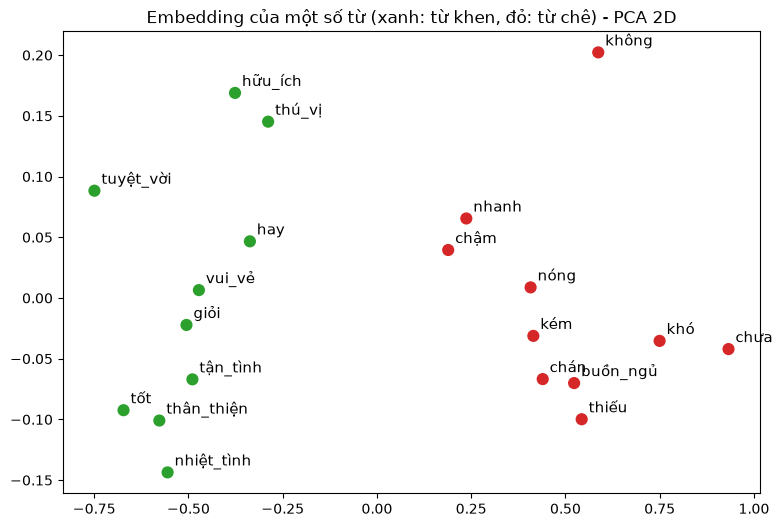

In [20]:
pos_words = ["hay", "tốt", "nhiệt_tình", "thân_thiện", "tận_tình", "vui_vẻ", "hữu_ích", "thú_vị", "giỏi", "tuyệt_vời"]
neg_words = ["chán", "nhanh", "nóng", "kém", "buồn_ngủ", "khó", "không", "chậm", "thiếu", "chưa"]

words, colors = [], []
for w, c in [(w, "tab:green") for w in pos_words] + [(w, "tab:red") for w in neg_words]:
    if w in word_index and word_index[w] < vocab_size:
        words.append(w)
        colors.append(c)

X = weights[[word_index[w] for w in words]]
X = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(X, full_matrices=False)    # PCA bằng SVD
X2 = X @ Vt[:2].T

plt.figure(figsize=(9, 6))
plt.scatter(X2[:, 0], X2[:, 1], c=colors, s=60)
for (x, y), w in zip(X2, words):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=11)
plt.title("Embedding của một số từ (xanh: từ khen, đỏ: từ chê) - PCA 2D")
plt.show()

**Nhận xét:** từ khen và từ chê tách thành **hai cụm ở hai phía** của mặt phẳng, giống hình "fun / unfunny" ở slide 22 của bài 3.5.

### Xuất embedding để xem trên TensorFlow Embedding Projector

Tải 2 file `vecs.tsv` và `meta.tsv` lên https://projector.tensorflow.org (bấm **Load**) để xoay và xem toàn bộ từ điển trong không gian 3D, giống hình ở slide 22 của bài 3.5.

In [21]:
with io.open("vecs.tsv", "w", encoding="utf-8") as out_v, io.open("meta.tsv", "w", encoding="utf-8") as out_m:
    for idx in range(2, vocab_size):               # bỏ padding (0) và <OOV> (1)
        out_m.write(reverse_word_index[idx] + "\n")
        out_v.write("\t".join(f"{x:.5f}" for x in weights[idx]) + "\n")
print("Đã ghi vecs.tsv và meta.tsv")

Đã ghi vecs.tsv và meta.tsv


## Bước 11. Lưu và nạp lại mô hình

Lưu 3 thứ để lần sau mở notebook **không cần huấn luyện lại**:
- `uit_vsfc_sentiment.keras`: mô hình
- `tokenizer.json`: từ điển
- `config.json`: `max_length` và các thiết lập padding

Lần sau chỉ cần chạy **Bước 1**, **ô định nghĩa hàm `preprocess` ở Bước 5**, rồi chạy ô *Nạp lại* bên dưới, sau đó chuyển thẳng tới Bước 12.

In [22]:
model.save("uit_vsfc_sentiment.keras")

with open("tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json(ensure_ascii=False))

with open("config.json", "w", encoding="utf-8") as f:
    json.dump({"max_length": max_length, "padding": padding_type,
               "truncating": trunc_type, "labels": LABEL_NAMES}, f, ensure_ascii=False, indent=2)

print("Đã lưu mô hình, tokenizer và config")

Đã lưu mô hình, tokenizer và config


In [23]:
# Nạp lại (dùng khi mở lại notebook mà không muốn huấn luyện lại)
model = tf.keras.models.load_model("uit_vsfc_sentiment.keras")

with open("tokenizer.json", encoding="utf-8") as f:
    tokenizer = tokenizer_from_json(f.read())

with open("config.json", encoding="utf-8") as f:
    config = json.load(f)
max_length, padding_type, trunc_type = config["max_length"], config["padding"], config["truncating"]

print("Đã nạp lại mô hình. max_length =", max_length)

Đã nạp lại mô hình. max_length = 24


## Bước 12. Test bằng câu tự gõ ⭐

Hàm `predict_sentiment` xử lý câu **giống hệt lúc huấn luyện**: làm sạch, tách từ bằng pyvi, đưa qua tokenizer, padding, rồi đưa vào mô hình.

> Mô hình học từ phản hồi của sinh viên, nên đoán tốt nhất với câu nói về **giảng viên, môn học, cơ sở vật chất, chương trình đào tạo**.

In [24]:
def predict_sentiment(text):
    processed = preprocess(text)
    seq = tokenizer.texts_to_sequences([processed])
    padded = pad_sequences(seq, maxlen=max_length, padding=padding_type, truncating=trunc_type)
    prob = float(model.predict(padded, verbose=0)[0][0])
    n_oov = sum(1 for t in seq[0] if t == 1)          # số từ mô hình chưa gặp
    return prob, processed, n_oov, len(seq[0])

def show_prediction(text):
    if not text.strip():
        print("Câu rỗng, hãy gõ lại.")
        return
    prob, processed, n_oov, n_tokens = predict_sentiment(text)
    if prob >= 0.5:
        print(f"→ TÍCH CỰC 😊  (độ tin cậy {prob:.1%})")
    else:
        print(f"→ TIÊU CỰC 😞  (độ tin cậy {1 - prob:.1%})")
    print(f"   sau tách từ: {processed}")
    if n_tokens and n_oov / n_tokens > 0.5:
        print(f"   ⚠ {n_oov}/{n_tokens} từ mô hình chưa gặp khi học, kết quả có thể không chính xác")

### 12.1 Thử với vài câu mẫu

In [25]:
examples = [
    "Thầy dạy rất nhiệt tình và dễ hiểu",
    "Cô giảng bài hay, luôn giúp đỡ sinh viên",
    "Môn học này rất bổ ích cho công việc sau này",
    "Thầy dạy nhanh quá, em không theo kịp",
    "Phòng học nóng, máy chiếu thường xuyên bị hư",
    "Bài tập quá nhiều mà không được giải thích",
    "Bài giảng soạn kĩ",          # viết "kĩ" (i ngắn): nhờ chuẩn hoá i/y vẫn hiểu được
]
for s in examples:
    print("Câu:", s)
    show_prediction(s)
    print()

Câu: Thầy dạy rất nhiệt tình và dễ hiểu


→ TÍCH CỰC 😊  (độ tin cậy 100.0%)
   sau tách từ: thầy dạy rất nhiệt_tình và dễ hiểu

Câu: Cô giảng bài hay, luôn giúp đỡ sinh viên
→ TÍCH CỰC 😊  (độ tin cậy 99.8%)
   sau tách từ: cô giảng bài hay luôn giúp_đỡ sinh_viên

Câu: Môn học này rất bổ ích cho công việc sau này
→ TÍCH CỰC 😊  (độ tin cậy 91.6%)
   sau tách từ: môn_học này rất bổ_ích cho công_việc sau_này

Câu: Thầy dạy nhanh quá, em không theo kịp
→ TIÊU CỰC 😞  (độ tin cậy 97.3%)
   sau tách từ: thầy dạy nhanh quá em không theo kịp

Câu: Phòng học nóng, máy chiếu thường xuyên bị hư
→ TIÊU CỰC 😞  (độ tin cậy 99.7%)
   sau tách từ: phòng học nóng máy_chiếu thường_xuyên bị hư

Câu: Bài tập quá nhiều mà không được giải thích


→ TIÊU CỰC 😞  (độ tin cậy 95.1%)
   sau tách từ: bài_tập quá nhiều mà không được giải_thích

Câu: Bài giảng soạn kĩ
→ TÍCH CỰC 😊  (độ tin cậy 85.7%)
   sau tách từ: bài giảng soạn kỹ



### 12.2 Tự gõ câu của bạn

Chạy ô bên dưới. Một **khung nhập chữ** và nút **Dự đoán** sẽ hiện ngay dưới ô code. Gõ câu nhận xét vào khung rồi bấm **Dự đoán**. Muốn thử câu khác thì sửa chữ trong khung và bấm lại, không cần chạy lại ô.

Nếu khung không hiện (thiếu `ipywidgets`), tạo một ô mới và gõ `show_prediction("câu của bạn")` rồi bấm **Shift + Enter**.

In [26]:
import ipywidgets as widgets
from IPython.display import display

o_nhap = widgets.Textarea(placeholder="Gõ câu nhận xét tiếng Việt ở đây...",
                          layout=widgets.Layout(width="100%", height="70px"))
nut = widgets.Button(description="Dự đoán", button_style="primary")
ket_qua = widgets.Output()

def khi_bam(_):
    with ket_qua:
        ket_qua.clear_output()
        print("Câu:", o_nhap.value)
        show_prediction(o_nhap.value)

nut.on_click(khi_bam)
display(o_nhap, nut, ket_qua)

Textarea(value='', layout=Layout(height='70px', width='100%'), placeholder='Gõ câu nhận xét tiếng Việt ở đây..…

Button(button_style='primary', description='Dự đoán', style=ButtonStyle())

Output()

### 12.3 (Tùy chọn) Giao diện web bằng Gradio

Đổi `RUN_GRADIO = True` rồi chạy ô bên dưới. Một giao diện có ô nhập chữ sẽ hiện ra, rất tiện để demo trước lớp. Trên Colab sẽ có thêm một đường link `gradio.live` để mở trên điện thoại.

In [27]:
RUN_GRADIO = False   # đổi thành True để mở giao diện web

if RUN_GRADIO:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

    def gradio_predict(text):
        prob, _, _, _ = predict_sentiment(text)
        return {"Tích cực 😊": prob, "Tiêu cực 😞": 1 - prob}

    gr.Interface(
        fn=gradio_predict,
        inputs=gr.Textbox(lines=3, placeholder="Nhập nhận xét về giảng viên, môn học..."),
        outputs=gr.Label(num_top_classes=2, label="Kết quả"),
        title="Phân tích cảm xúc phản hồi sinh viên",
        description="Mô hình Embedding + Bi-LSTM huấn luyện trên UIT-VSFC",
        examples=examples,
    ).launch(share=True)

## Bước 13. Kết luận

**Kết quả đạt được**
- Đã xây dựng quy trình đầy đủ: tải dữ liệu, làm sạch, tách từ tiếng Việt, Tokenizer, padding, Embedding + Bi-LSTM, đánh giá, demo.
- Trên tập test (khoảng 3.000 câu chưa từng thấy khi học), mô hình đạt **accuracy khoảng 93–94%**, F1 của cả hai lớp khoảng 0,93–0,94 (số chính xác xem ở **Bước 9**; mỗi lần chạy có thể lệch một chút).
- Lớp Embedding tự học được nghĩa cảm xúc của từ chỉ từ nhãn tích cực/tiêu cực: các từ khen nằm gần nhau, các từ chê nằm gần nhau (**Bước 10**).

**Hạn chế**
- Đã bỏ lớp trung tính vì quá ít dữ liệu (khoảng 4%), nên mô hình luôn trả về tích cực hoặc tiêu cực, kể cả với câu trung tính.
- Dữ liệu chỉ thuộc lĩnh vực giáo dục, nên câu ở lĩnh vực khác (phim, đồ ăn, sản phẩm) thường có nhiều từ `<OOV>` và kết quả kém hơn.
- Câu mỉa mai hoặc câu vừa khen vừa chê vẫn dễ bị đoán sai (xem các câu sai ở **Bước 9**).
- Mô hình chưa xử lý được viết tắt, teencode, hoặc câu không dấu. Mỗi cách viết khác nhau là một token riêng: ví dụ "kĩ" và "kỹ" ban đầu bị coi là 2 từ khác nhau. Bước 5 mới chỉ chuẩn hoá vài trường hợp i/y phổ biến, các lỗi chính tả khác vẫn thành `<OOV>`.
- pyvi đôi khi không ghép đúng từ, ví dụ "dễ hiểu" vẫn bị tách thành "dễ" và "hiểu".

**Hướng phát triển**
- Dùng embedding huấn luyện sẵn cho tiếng Việt (FastText `cc.vi.300`, PhoW2V) thay vì học từ đầu.
- Giữ cả 3 lớp, dùng `class_weight` hoặc tăng cường dữ liệu cho lớp trung tính.
- Dùng mô hình ngôn ngữ lớn cho tiếng Việt như PhoBERT.